# 6. Demanda, clima e hidrología

Se estiman asociaciones contemporáneas, asociaciones con covariables rezagadas 24 horas y acumulados hidrológicos retrospectivos. La información mutua se calcula sobre una muestra determinista de entrenamiento. Estas medidas describen dependencias estadísticas y orientan la representación multivariada.

Las ocho ciudades se conservan por separado para representar la heterogeneidad meteorológica. El objetivo de pronóstico es una serie nacional. La precipitación urbana caracteriza las ubicaciones seleccionadas; representar la oferta hidroeléctrica mediante lluvia requiere observaciones adicionales en las cuencas aportantes.


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from IPython.display import Markdown, display
from sklearn.feature_selection import mutual_info_regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
SEED = 11037
TARGET = 'precio_bolsa_cop_kwh'
RESULTS = ROOT / 'results'
SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
TIME = 'timestamp_start_colombia'
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [5]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [6]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

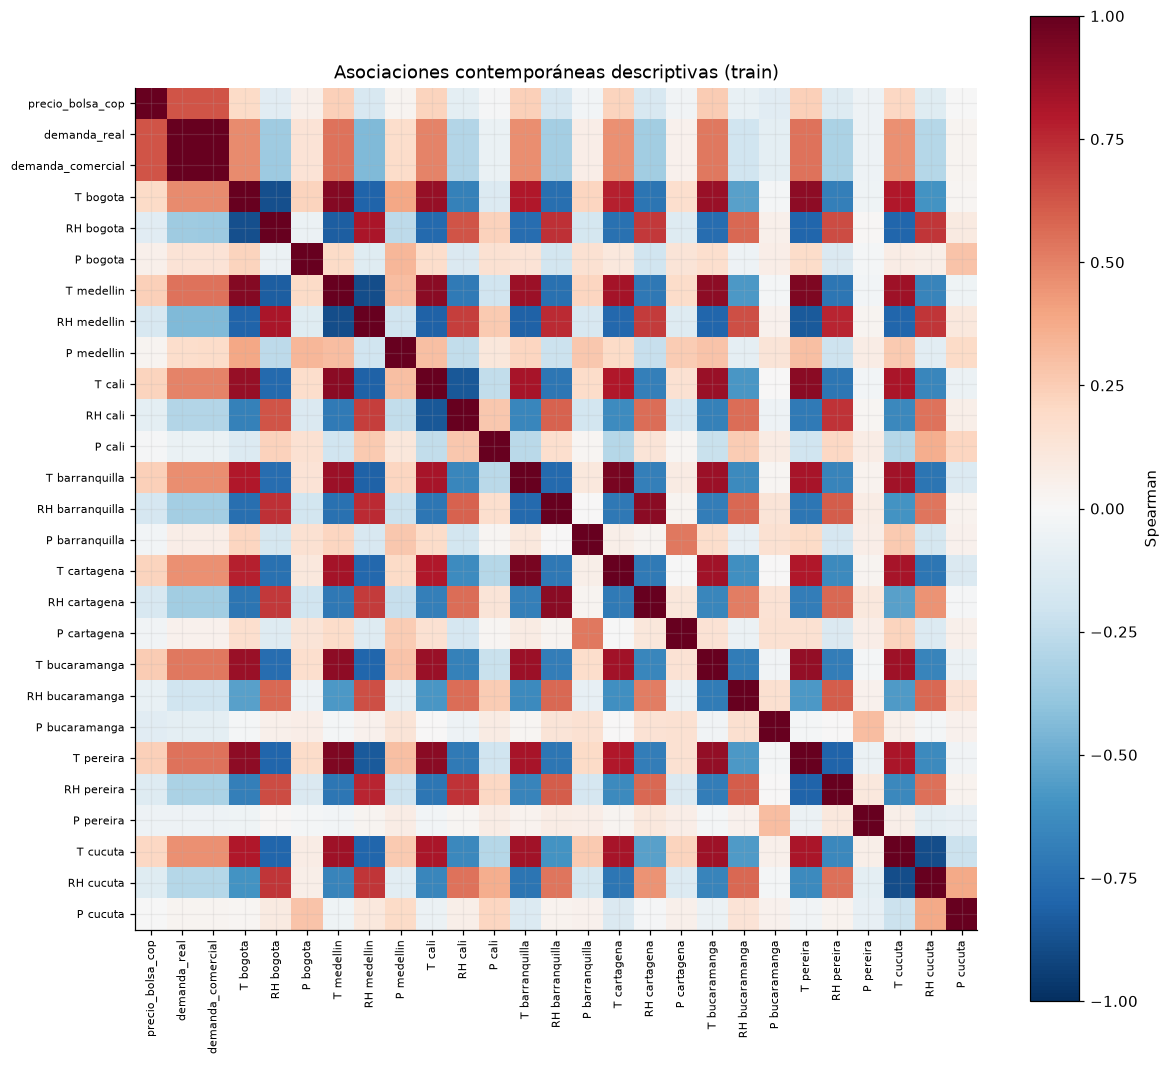

In [7]:
frame = load_numeric()
hydro = load_numeric(table='hydrology')
numeric = frame.select_dtypes('number').drop(columns=['xm_hour'], errors='ignore')
corr = numeric.corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
labels = [c.replace('relative_humidity_2m_pct_', 'RH ').replace('temperature_2m_c_', 'T ').replace('precipitation_preceding_hour_mm_', 'P ').replace('_kwh', '') for c in corr]
ax.set_xticks(range(len(corr)), labels, rotation=90, fontsize=7)
ax.set_yticks(range(len(corr)), labels, fontsize=7)
fig.colorbar(im, ax=ax, label='Spearman')
ax.set_title('Asociaciones contemporáneas descriptivas (train)')
figure(fig, 'correlaciones_train')

In [8]:
table(corr[[TARGET]].sort_values(TARGET), 'correlacion_contemporanea_train')

,precio_bolsa_cop_kwh
relative_humidity_2m_pct_barranquilla,-0.16484
relative_humidity_2m_pct_cartagena,-0.1604
relative_humidity_2m_pct_medellin,-0.15985
relative_humidity_2m_pct_pereira,-0.12652
relative_humidity_2m_pct_cucuta,-0.12198
relative_humidity_2m_pct_bogota,-0.11151
precipitation_preceding_hour_mm_bucaramanga,-0.11003
relative_humidity_2m_pct_cali,-0.099551
relative_humidity_2m_pct_bucaramanga,-0.070865
precipitation_preceding_hour_mm_pereira,-0.047244


In [9]:
predictors = numeric.drop(columns=TARGET).shift(24)
aligned = predictors.join(frame[TARGET]).dropna()
rng = np.random.default_rng(SEED)
idx = np.sort(rng.choice(len(aligned), min(12000, len(aligned)), replace=False))
sample = aligned.iloc[idx]
mi = mutual_info_regression(sample.drop(columns=TARGET), sample[TARGET], n_neighbors=5, random_state=SEED)
lagged = pd.DataFrame({'spearman_rezago_24h': aligned.corr(method='spearman')[TARGET].drop(TARGET), 'informacion_mutua_muestra_train': mi}, index=predictors.columns).sort_values('spearman_rezago_24h')
table(lagged, 'asociaciones_rezagadas_train')

,spearman_rezago_24h,informacion_mutua_muestra_train
relative_humidity_2m_pct_barranquilla,-0.16752,0.041177
relative_humidity_2m_pct_medellin,-0.16461,0.034723
relative_humidity_2m_pct_cartagena,-0.16291,0.047077
relative_humidity_2m_pct_pereira,-0.12976,0.02586
relative_humidity_2m_pct_cucuta,-0.12824,0.039703
relative_humidity_2m_pct_bogota,-0.11723,0.037738
precipitation_preceding_hour_mm_bucaramanga,-0.11564,0.016464
relative_humidity_2m_pct_cali,-0.10089,0.011836
relative_humidity_2m_pct_bucaramanga,-0.077291,0.0091161
precipitation_preceding_hour_mm_pereira,-0.048003,0.021154


In [10]:
x = numeric.drop(columns=TARGET)
std = x.std()
z = (x - x.mean()) / std.replace(0, np.nan)
matrix = z.dropna(axis=1).to_numpy()
condition = np.linalg.cond(matrix[::24])
gram = np.corrcoef(matrix[::24], rowvar=False)
vif = np.diag(np.linalg.pinv(gram))
table(pd.DataFrame({'VIF_aproximado': vif}, index=z.dropna(axis=1).columns).sort_values('VIF_aproximado', ascending=False), 'colinealidad_train')

,VIF_aproximado
demanda_real_kwh,863.61
demanda_comercial_kwh,861.22
temperature_2m_c_barranquilla,10.665
temperature_2m_c_cartagena,8.6616
relative_humidity_2m_pct_barranquilla,6.348
temperature_2m_c_cucuta,4.5652
relative_humidity_2m_pct_cartagena,4.4872
temperature_2m_c_cali,4.3426
relative_humidity_2m_pct_cucuta,3.9774
temperature_2m_c_bucaramanga,3.4348


In [11]:
display(Markdown(f'Número de condición de la matriz estandarizada diaria de covariables: **{condition:.4g}**. El VIF usa pseudoinversa si hay singularidad; se interpreta junto al número de condición, no como identificación causal.'))

Número de condición de la matriz estandarizada diaria de covariables: **189.1**. El VIF usa pseudoinversa si hay singularidad; se interpreta junto al número de condición, no como identificación causal.

In [12]:
daily = frame[TARGET].resample('D').mean()
h = hydro.select_dtypes('number')
changes = pd.DataFrame({'precio_diario': daily, 'reserva_rezago_1d': h['reserva_util_kwh'].shift(1), 'aportes_acumulados_7d_pasados': h['aportes_kwh_dia'].shift(1).rolling(7).sum(), 'cambio_reserva_7d_pasado': h['reserva_util_kwh'].shift(1) - h['reserva_util_kwh'].shift(8)})
table(changes.corr(method='spearman'), 'hidrologia_cambios_pasados_train')

,precio_diario,reserva_rezago_1d,aportes_acumulados_7d_pasados,cambio_reserva_7d_pasado
precio_diario,1,-0.25455,-0.13292,-0.23034
reserva_rezago_1d,-0.25455,1,0.31059,0.084981
aportes_acumulados_7d_pasados,-0.13292,0.31059,1,0.82355
cambio_reserva_7d_pasado,-0.23034,0.084981,0.82355,1


In [13]:
weather = []
for c in numeric:
    if any((s in c for s in ['temperature', 'humidity', 'precipitation'])):
        weather.append(dict(variable=c, media=numeric[c].mean(), sd=numeric[c].std(), p01=numeric[c].quantile(0.01), p99=numeric[c].quantile(0.99)))
table(pd.DataFrame(weather).set_index('variable'), 'heterogeneidad_ciudades_train')

,media,sd,p01,p99
variable,,,,
temperature_2m_c_bogota,14.903,3.4963,9.1,22.7
relative_humidity_2m_pct_bogota,75.278,19.113,31,100
precipitation_preceding_hour_mm_bogota,0.1093,0.38829,0,1.7
temperature_2m_c_medellin,21.057,3.5071,15.7,29.1
relative_humidity_2m_pct_medellin,84.593,15.322,43,100
precipitation_preceding_hour_mm_medellin,0.32341,0.72186,0,3.5
temperature_2m_c_cali,22.283,2.8215,17.5,28.6
relative_humidity_2m_pct_cali,83.762,9.4969,59,98
precipitation_preceding_hour_mm_cali,0.35617,0.94759,0,4.6


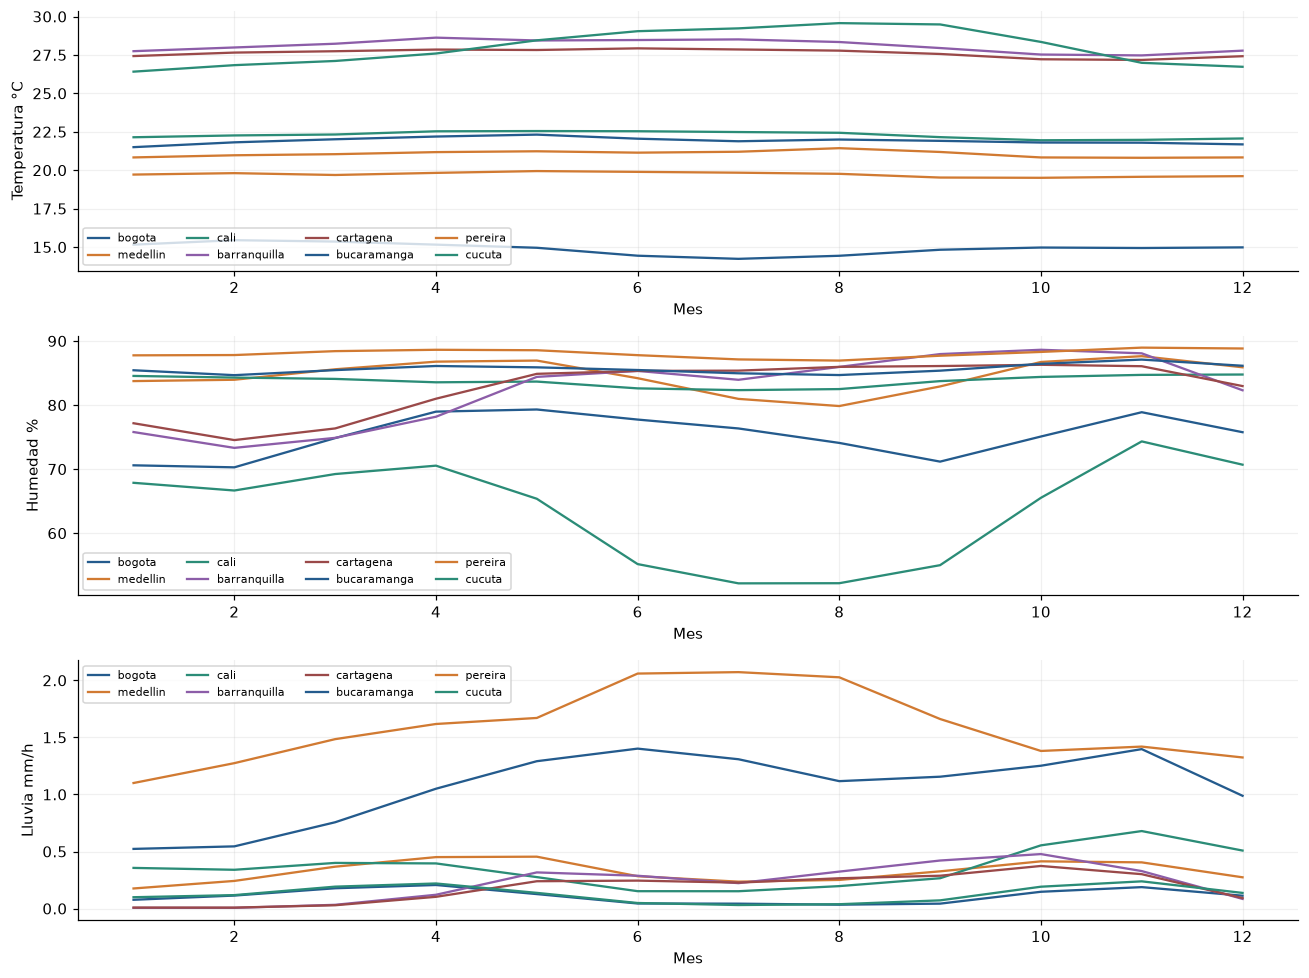

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9))
for ax, prefix, label in zip(axes, ['temperature', 'relative_humidity', 'precipitation'], ['Temperatura °C', 'Humedad %', 'Lluvia mm/h']):
    cols = [c for c in numeric if c.startswith(prefix)]
    means = numeric[cols].groupby(frame.index.month).mean()
    means.columns = [c.rsplit('_', 1)[-1] for c in cols]
    means.plot(ax=ax)
    ax.set(xlabel='Mes', ylabel=label)
    ax.legend(ncol=4, fontsize=7)
figure(fig, 'clima_por_ciudad_train')

In [15]:
decision('Conservar las ocho ciudades. Acumulados y cambios sólo hacia atrás; estandarización/selección sólo con train.', 'Bloques numéricos de demanda, clima e hidrología y fusión aprendida; regularizar ante covariables redundantes.', 'Asociaciones contemporáneas y con rezago son EDA retrospectivo, no evidencia de información conocida ni ganancia fuera de muestra.', 'Demanda realizada del horizonte y clima futuro realizado producirían fuga. Un día de rezago hidrológico es ilustración, no un rezago de publicación certificado. Lluvia urbana no reemplaza lluvia de cuencas aportantes; esta última no está descargada.')

### Implicaciones del análisis

- **Preprocesamiento:** Conservar las ocho ciudades. Acumulados y cambios sólo hacia atrás; estandarización/selección sólo con train.
- **Arquitectura:** Bloques numéricos de demanda, clima e hidrología y fusión aprendida; regularizar ante covariables redundantes.
- **Validación:** Asociaciones contemporáneas y con rezago son EDA retrospectivo, no evidencia de información conocida ni ganancia fuera de muestra.
- **Riesgos:** Demanda realizada del horizonte y clima futuro realizado producirían fuga. Un día de rezago hidrológico es ilustración, no un rezago de publicación certificado. Lluvia urbana no reemplaza lluvia de cuencas aportantes; esta última no está descargada.